# Unidad 5 — Proyecto final: del modelo a la decisión

**Módulo 6: Modelos Avanzados de IA y Aplicaciones Económicas — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 24-11-2026 · **en clase, individual, 2 horas** · Contenidos 5.1 a 5.5 · **Proyecto final: 40 puntos**

Un banco quiere decidir **a qué clientes de tarjeta llamar** para ofrecerles un plan de pagos antes de que dejen de pagar.
Llamar cuesta; no llamar a quien termina sin pagar cuesta más. En este proyecto recorres, **paso a paso**, todo lo que vimos en el módulo
para llegar a una recomendación.

## Cómo se trabaja

- El notebook **ya funciona completo**. No hay que programar: en el **Paso 1** cambias un solo número, **tu escenario**, y ejecutas las celdas en orden.
- Cada paso termina con un recuadro **📝 Al formulario**: las respuestas se escriben en el **Instrumento 05** (formulario), no aquí.
- Cada participante tiene un **escenario** (costos y segmento de clientes): es su número en la lista del curso; si es mayor que 8, se le resta 8 las veces necesarias. Los números cambian de un escenario a otro.
- **Es un trabajo individual:** cada participante entrega su propio formulario.
- **Se entrega:** el formulario del Instrumento 05 en PDF al terminar la clase.

## Los ocho pasos

| Paso | Qué haces | Tiempo | Lo que vimos en |
|---|---|---|---|
| 1 | Tu escenario: la decisión y el umbral | 10 min | U2 · decidir con costos |
| 2 | Línea base y Bayes a mano | 10 min | U1 · línea base · U2 · Bayes |
| 3 | Tu segmento: creencias con la Beta | 10 min | U2 · intervalos creíbles |
| 4 | Tres modelos en Validation | 10 min | U1 · Random Forest · U2 · Naive Bayes · U3 · neurona |
| 5 | ¿Sus probabilidades son creíbles? | 10 min | U2 · calibración |
| 6 | Decidir con costos | 15 min | U2 y U4 · costos |
| 7 | El Test, una sola vez | 10 min | U4 · evaluación final e intervalo |
| 8 | La ficha ejecutiva | 15 min | U4 · comunicar |

Los últimos 10 a 15 minutos de la clase, algunos participantes comparten su recomendación.

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [1]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib scikit-learn scipy

In [2]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo6_modelos_avanzados_ia_aplicaciones_economicas/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'impago_tarjetas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /home/claude/m6/datos


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
import warnings
warnings.filterwarnings('ignore')

# Paso 1 · Tu escenario: la decisión y el umbral (10 min)

El **escenario 0** lo resuelve el docente en clase, paso a paso, como ejemplo. Después cada participante repite con el **escenario** que corresponde a su número en la lista (del 1 al 8). Cada escenario tiene:

- **el costo de llamar** a un cliente (en dólares por cliente);
- **el costo de un impago no gestionado** (lo que pierde el banco si no llamó y el cliente no pagó);
- **un segmento de clientes** que el gerente quiere revisar en el Paso 3.

| Escenario | Llamar cuesta | Impago no gestionado cuesta | Segmento |
|---|---|---|---|
| **0** | **1** | **6** | **casados** (lo resuelve el docente en clase, como ejemplo) |
| 1 | 1 | 5 | clientes de 60 años o más |
| 2 | 2 | 5 | estado civil "otro" |
| 3 | 1 | 10 | educación "otros" |
| 4 | 3 | 10 | cupo de 500 000 o más |
| 5 | 1 | 4 | menores de 25 años |
| 6 | 1 | 3 | cupo de 30 000 o menos |
| 7 | 1 | 8 | no pagaron nada en septiembre |
| 8 | 3 | 5 | de 50 a 59 años |

**Recuerda la regla de la Unidad 2:** si la probabilidad de impago es *p*, no llamar cuesta *impago × p* y llamar cuesta *llamar*. Conviene llamar cuando

$$p > \frac{\text{costo de llamar}}{\text{costo del impago}}$$

👉 **TU TURNO:** el notebook viene con el escenario 0 (el ejemplo del docente). Cámbialo por el tuyo y ejecuta la celda.

In [4]:
ESCENARIO = 0          # <-- TU TURNO: el 0 es el ejemplo del docente; escribe aquí el número de tu escenario (1 a 8)

ESCENARIOS = {
    0: dict(llamar=1, impago=6,  segmento='casados',                        filtro=lambda d: d['estado_civil'] == 1),
    1: dict(llamar=1, impago=5,  segmento='clientes de 60 años o más',      filtro=lambda d: d['edad'] >= 60),
    2: dict(llamar=2, impago=5,  segmento='estado civil "otro"',            filtro=lambda d: d['estado_civil'] == 3),
    3: dict(llamar=1, impago=10, segmento='educación "otros"',              filtro=lambda d: d['educacion'] >= 4),
    4: dict(llamar=3, impago=10, segmento='cupo de 500 000 o más',          filtro=lambda d: d['limite_credito'] >= 500_000),
    5: dict(llamar=1, impago=4,  segmento='menores de 25 años',             filtro=lambda d: d['edad'] < 25),
    6: dict(llamar=1, impago=3,  segmento='cupo de 30 000 o menos',         filtro=lambda d: d['limite_credito'] <= 30_000),
    7: dict(llamar=1, impago=8,  segmento='no pagaron nada en septiembre',  filtro=lambda d: d['pago_sep'] == 0),
    8: dict(llamar=3, impago=5,  segmento='de 50 a 59 años',                filtro=lambda d: d['edad'].between(50, 59)),
}
esc = ESCENARIOS[ESCENARIO]
UMBRAL = esc['llamar'] / esc['impago']

print(f'Escenario {ESCENARIO}')
print(f'  Llamar cuesta {esc["llamar"]} · un impago no gestionado cuesta {esc["impago"]}')
print(f'  Umbral de decisión: llamar si p > {esc["llamar"]} / {esc["impago"]} = {UMBRAL:.3f}')
print(f'  Segmento a revisar en el Paso 3: {esc["segmento"]}')

Escenario 0
  Llamar cuesta 1 · un impago no gestionado cuesta 6
  Umbral de decisión: llamar si p > 1 / 6 = 0.167
  Segmento a revisar en el Paso 3: casados


> 📝 **Al formulario (pregunta 1):** escribe con tus palabras qué decisión apoya el modelo y quién la toma, y calcula **a mano** el umbral de tu escenario. ¿Es mayor o menor que 0,5? ¿Qué significa eso para el banco?

# Paso 2 · Línea base y Bayes a mano (10 min)

Cargamos los datos con **la misma partición de todo el módulo**: Train para aprender, Validation para comparar y elegir, Test para el final.

In [5]:
datos = pd.read_csv(DATA_DIR / 'impago_tarjetas.csv')

# X: lo que sabemos del cliente en septiembre · y: si no pagó en octubre (1 = impago)
X = datos.drop(columns=['id', 'impago'])
y = datos['impago']

# La misma partición en todo el módulo (misma semilla): 60 % Train, 20 % Validation, 20 % Test.
# stratify=y mantiene el 22 % de impagos en las tres partes.
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42)

print('Train:', X_train.shape, '· Validation:', X_val.shape, '· Test:', X_test.shape)
print('Tasa de impago -> Train:', round(y_train.mean(), 3), '· Validation:', round(y_val.mean(), 3), '· Test:', round(y_test.mean(), 3))

Train: (18000, 23) · Validation: (6000, 23) · Test: (6000, 23)
Tasa de impago -> Train: 0.221 · Validation: 0.221 · Test: 0.221


**La línea base** es la regla simple de la Unidad 1: *alerta* si el cliente tiene **2 o más meses de atraso en septiembre**.
Antes de cualquier modelo, la usamos con el teorema de Bayes, **contando**, como en la Unidad 2.

In [6]:
alerta_train = (X_train['atraso_sep'] >= 2).astype(int)
tabla = pd.crosstab(alerta_train.rename('alerta'), y_train.rename('impago'), margins=True, margins_name='Total')
tabla

impago,0,1,Total
alerta,,,
0,13455,2660,16115
1,563,1322,1885
Total,14018,3982,18000


In [7]:
# Las mismas cuentas que haces a mano (compruébalas después de hacerlas)
con_alerta_impago = tabla.loc[1, 1]
print('P(impago)            =', tabla.loc['Total', 1], '/', tabla.loc['Total', 'Total'], '=', round(y_train.mean(), 3))
print('P(alerta | impago)   =', con_alerta_impago, '/', tabla.loc['Total', 1], '=', round(con_alerta_impago / tabla.loc['Total', 1], 3))
print('P(impago | alerta)   =', con_alerta_impago, '/', tabla.loc[1, 'Total'], '=', round(con_alerta_impago / tabla.loc[1, 'Total'], 3))
print('P(impago | sin alerta) =', tabla.loc[0, 1], '/', tabla.loc[0, 'Total'], '=', round(tabla.loc[0, 1] / tabla.loc[0, 'Total'], 3))

# ¿Cuánto vale la regla para ordenar clientes? La medimos en Validation con el AUC, ordenando por meses de atraso
alerta_val = (X_val['atraso_sep'] >= 2).astype(int)
print('\nAUC de la regla en Validation (ordenando por meses de atraso):', round(roc_auc_score(y_val, X_val['atraso_sep']), 3))

P(impago)            = 3982 / 18000 = 0.221
P(alerta | impago)   = 1322 / 3982 = 0.332
P(impago | alerta)   = 1322 / 1885 = 0.701
P(impago | sin alerta) = 2660 / 16115 = 0.165



AUC de la regla en Validation (ordenando por meses de atraso): 0.683


> 📝 **Al formulario (pregunta 2):** con la tabla de arriba, calcula **a mano** P(impago | alerta) y P(alerta | impago). ¿Por qué son distintas? Según tu umbral del Paso 1, ¿el banco debería llamar a los clientes con alerta?

# Paso 3 · Tu segmento: creencias con la Beta (10 min)

El gerente pregunta: **¿el segmento de mi escenario es más riesgoso que la cartera general?**

Usamos la Beta de la Unidad 2. El prior **Beta(2,2; 7,8)** es "como haber visto 10 clientes con 22 % de impago". Después sumamos lo que vemos:

$$\text{Beta}(a, b) + k \text{ impagos} + m \text{ pagos} \rightarrow \text{Beta}(a + k,\ b + m)$$

Primero con **los primeros 30 clientes** del segmento (lo que tendría un analista apurado) y después con **todos** los del segmento en Train.

In [8]:
seg = y_train[esc['filtro'](X_train)]
tasa_general = y_train.mean()
a0, b0 = 2.2, 7.8

filas = []
for nombre, datos_seg in [('Primeros 30 clientes', seg.iloc[:30]), (f'Todos ({len(seg)} clientes)', seg)]:
    k, m = int(datos_seg.sum()), int(len(datos_seg) - datos_seg.sum())
    a, b = a0 + k, b0 + m
    lo, hi = stats.beta.ppf([0.025, 0.975], a, b)
    filas.append({'Datos': nombre, 'Impagos (k)': k, 'Pagos (m)': m, 'Posterior': f'Beta({a:.1f}; {b:.1f})',
                  'Media': round(a / (a + b), 3), 'IC 95 % desde': round(lo, 3), 'IC 95 % hasta': round(hi, 3),
                  'P(más riesgoso que la cartera)': round(1 - stats.beta.cdf(tasa_general, a, b), 3)})
print(f'Segmento: {esc["segmento"]} · tasa general de la cartera: {tasa_general:.3f}')
resumen_seg = pd.DataFrame(filas).set_index('Datos')
resumen_seg

Segmento: casados · tasa general de la cartera: 0.221


,Impagos (k),Pagos (m),Posterior,Media,IC 95 % desde,IC 95 % hasta,P(más riesgoso que la cartera)
Datos,,,,,,,
Primeros 30 clientes,2,28,Beta(4.2; 35.8),0.105,0.031,0.216,0.021
Todos (8137 clientes),1871,6266,Beta(1873.2; 6273.8),0.230,0.221,0.239,0.970


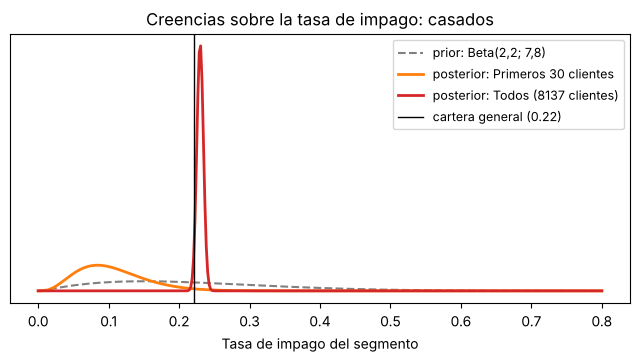

In [9]:
th = np.linspace(0, 0.8, 400)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(th, stats.beta.pdf(th, a0, b0), '--', color='gray', label='prior: Beta(2,2; 7,8)')
for (nombre, fila), color in zip(resumen_seg.iterrows(), ['tab:orange', 'tab:red']):
    k, m = fila['Impagos (k)'], fila['Pagos (m)']
    ax.plot(th, stats.beta.pdf(th, a0 + k, b0 + m), color=color, lw=2, label=f'posterior: {nombre}')
ax.axvline(tasa_general, color='black', lw=1, label=f'cartera general ({tasa_general:.2f})')
ax.set_xlabel('Tasa de impago del segmento'); ax.set_yticks([]); ax.legend(fontsize=9)
ax.set_title(f'Creencias sobre la tasa de impago: {esc["segmento"]}')
plt.show()

> 📝 **Al formulario (pregunta 3):** comprueba **a mano** la media del posterior con los 30 clientes: (2,2 + k) / (10 + 30) = (2,2 + k) / 40. ¿Qué le respondes al gerente? Usa el intervalo y la última columna. ¿Por qué la curva con todos los clientes es más estrecha?

# Paso 4 · Tres modelos en Validation (10 min)

Entrenamos con Train tres modelos del módulo y los comparamos con la regla **en Validation**, con dos preguntas:

- **AUC:** ¿ordena bien a los clientes de más a menos riesgoso?
- **Brier:** ¿sus probabilidades son creíbles? Es el error entre la probabilidad que dijo el modelo y lo que pasó. **Menos es mejor.** Como referencia, decir siempre la tasa general da el Brier de "no saber nada".

La **regla del atraso** también entra: como probabilidad dice P(impago | alerta) a quien tiene alerta y P(impago | sin alerta) a quien no (las cuentas del Paso 2); para ordenar, usa los meses de atraso.

La **regresión logística** es una sola neurona (Unidad 3). Todo tarda unos 20 segundos.

In [10]:
modelos = {
    'Naive Bayes': make_pipeline(StandardScaler(), GaussianNB()),
    'Regresión logística (una neurona)': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
}
# La regla como probabilidad: lo que contamos en el Paso 2 (Bayes con la alerta)
p_alerta, p_sin = con_alerta_impago / tabla.loc[1, 'Total'], tabla.loc[0, 1] / tabla.loc[0, 'Total']
prob_val = {'Regla del atraso': np.where(alerta_val == 1, p_alerta, p_sin)}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    prob_val[nombre] = modelo.predict_proba(X_val)[:, 1]

comparacion = pd.DataFrame({nombre: {'AUC': roc_auc_score(y_val, p), 'Brier': brier_score_loss(y_val, p)} for nombre, p in prob_val.items()}).T
comparacion.loc['Regla del atraso', 'AUC'] = roc_auc_score(y_val, X_val['atraso_sep'])   # para ordenar, la regla usa los meses de atraso
comparacion.loc['Siempre la tasa general'] = [0.5, brier_score_loss(y_val, np.full(len(y_val), y_train.mean()))]
comparacion.round(3)

,AUC,Brier
Regla del atraso,0.683,0.148
Naive Bayes,0.734,0.216
Regresión logística (una neurona),0.724,0.145
Random Forest,0.783,0.135
Siempre la tasa general,0.500,0.172


> 📝 **Al formulario (pregunta 4):** copia el AUC y el Brier de los cuatro modelos. ¿Cuál ordena mejor? ¿Alguno tiene un Brier **peor** que "siempre la tasa general"? ¿Qué significa eso?

# Paso 5 · ¿Sus probabilidades son creíbles? (10 min)

La **curva de calibración** agrupa a los clientes según la probabilidad que les dio el modelo y mira cuántos no pagaron de verdad.
Si el modelo es honesto, los puntos caen sobre la diagonal.

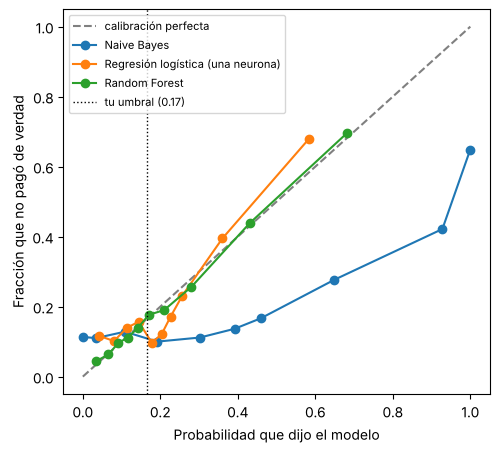

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], '--', color='gray', label='calibración perfecta')
for nombre in modelos:
    obs, pred = calibration_curve(y_val, prob_val[nombre], n_bins=10, strategy='quantile')
    ax.plot(pred, obs, 'o-', label=nombre)
ax.axvline(UMBRAL, color='black', lw=1, ls=':', label=f'tu umbral ({UMBRAL:.2f})')
ax.set_xlabel('Probabilidad que dijo el modelo'); ax.set_ylabel('Fracción que no pagó de verdad'); ax.legend(fontsize=8)
plt.show()

> 📝 **Al formulario (pregunta 5):** ¿qué modelo se aleja más de la diagonal? Mira la zona de **tu umbral** (línea punteada): si el modelo dice "0,40", ¿de verdad no paga el 40 %? ¿Por qué esto importa para decidir con costos?

# Paso 6 · Decidir con costos (15 min)

Ahora cada probabilidad se convierte en una decisión: **llamar si p > umbral**. Para cada cliente de Validation:

| Si el banco... | y el cliente... | cuesta |
|---|---|---|
| llama | (paga o no) | el costo de llamar |
| no llama | no paga | el costo del impago |
| no llama | paga | 0 |

Comparamos **tu umbral** con el umbral "de siempre", 0,5, con la **regla actual del banco** (llamar a quien tiene alerta) y con dos políticas sin modelo: **no llamar a nadie** y **llamar a todos**.

In [12]:
def costo_total(prob, y_real, umbral):
    llamar = prob > umbral
    return int((llamar * esc['llamar'] + (~llamar & (y_real.values == 1)) * esc['impago']).sum())

filas = {'No llamar a nadie': {'Umbral 0,5': costo_total(np.zeros(len(y_val)), y_val, 0.5), 'Tu umbral': costo_total(np.zeros(len(y_val)), y_val, UMBRAL)},
         'Llamar a todos': {'Umbral 0,5': costo_total(np.ones(len(y_val)), y_val, 0.5), 'Tu umbral': costo_total(np.ones(len(y_val)), y_val, UMBRAL)}}
for nombre, p in prob_val.items():
    if nombre == 'Regla del atraso':     # la regla actual del banco: llamar a quien tiene alerta, sin importar el umbral
        p = alerta_val.values.astype(float)
    filas[nombre] = {'Umbral 0,5': costo_total(p, y_val, 0.5), 'Tu umbral': costo_total(p, y_val, UMBRAL)}
costos_val = pd.DataFrame(filas).T
costos_val['Clientes a llamar (tu umbral)'] = [0, len(y_val)] + [int(alerta_val.sum())] + [int((prob_val[m] > UMBRAL).sum()) for m in modelos]
print(f'Costo total en Validation (6 000 clientes) · llamar {esc["llamar"]}, impago {esc["impago"]}, umbral {UMBRAL:.3f}')
costos_val.sort_values('Tu umbral')

Costo total en Validation (6 000 clientes) · llamar 1, impago 6, umbral 0.167


,"Umbral 0,5",Tu umbral,Clientes a llamar (tu umbral)
Random Forest,5805,4559,2765
Regresión logística (una neurona),6441,5421,3531
Naive Bayes,4916,5441,4067
Llamar a todos,6000,6000,6000
Regla del atraso,6075,6075,609
No llamar a nadie,7962,7962,0


In [13]:
# El modelo elegido es el de MENOR costo con tu umbral, entre los tres modelos (la regla queda como línea base)
ELEGIDO = costos_val.loc[list(modelos), 'Tu umbral'].idxmin()
print('Modelo elegido en Validation:', ELEGIDO)
print('Costo con tu umbral:', costos_val.loc[ELEGIDO, 'Tu umbral'], '· regla del atraso:', costos_val.loc['Regla del atraso', 'Tu umbral'])

Modelo elegido en Validation: Random Forest
Costo con tu umbral: 4559 · regla del atraso: 6075


> 📝 **Al formulario (pregunta 6):** ¿qué política cuesta menos? ¿Cuánto ahorra el modelo elegido frente a la regla y frente a "no llamar a nadie"? ¿Bajar o subir el umbral de 0,5 al tuyo **mejoró** el costo de todos los modelos? Si alguno empeoró, ¿por qué crees que pasó? (Pista: el Paso 5.)

# Paso 7 · El Test, una sola vez (10 min)

El modelo ya está elegido **con Validation**. Ahora, y solo ahora, lo medimos en **Test**: 6 000 clientes que nadie usó para decidir.

Para saber **cuánto confiar** en el ahorro, usamos el **bootstrap** de la Unidad 4: repetimos el cálculo con 1 000 muestras de clientes del Test, tomadas con reemplazo, y miramos entre qué valores queda el ahorro el 95 % de las veces.

In [14]:
p_test_modelo = modelos[ELEGIDO].predict_proba(X_test)[:, 1]
p_test_regla = (X_test['atraso_sep'] >= 2).astype(float).values

def costo_por_cliente(prob, y_real, umbral):
    llamar = prob > umbral
    return llamar * esc['llamar'] + (~llamar & (y_real.values == 1)) * esc['impago']

c_modelo = costo_por_cliente(p_test_modelo, y_test, UMBRAL)
c_regla = costo_por_cliente(p_test_regla, y_test, UMBRAL)
c_nadie = costo_por_cliente(np.zeros(len(y_test)), y_test, UMBRAL)

rng = np.random.default_rng(42)
idx = rng.integers(0, len(y_test), size=(1000, len(y_test)))
ahorro_boot = (c_regla[idx] - c_modelo[idx]).sum(axis=1)
lo, hi = np.percentile(ahorro_boot, [2.5, 97.5])

print(f'TEST · escenario {ESCENARIO} · modelo elegido: {ELEGIDO}')
print(f'  AUC del modelo: {roc_auc_score(y_test, p_test_modelo):.3f} · AUC de la regla: {roc_auc_score(y_test, X_test["atraso_sep"]):.3f}')
print(f'  Costo total -> modelo: {c_modelo.sum():,.0f} · regla: {c_regla.sum():,.0f} · no llamar a nadie: {c_nadie.sum():,.0f}')
print(f'  Ahorro del modelo frente a la regla: {c_regla.sum() - c_modelo.sum():,.0f}')
print(f'  Intervalo del 95 % del ahorro (bootstrap): de {lo:,.0f} a {hi:,.0f}')
print('  ¿El intervalo excluye el cero?', 'Sí: el ahorro es claro.' if lo > 0 or hi < 0 else 'No: con estos datos no se puede asegurar que el modelo ahorre.')

TEST · escenario 0 · modelo elegido: Random Forest
  AUC del modelo: 0.768 · AUC de la regla: 0.676
  Costo total -> modelo: 4,798 · regla: 5,964 · no llamar a nadie: 7,962
  Ahorro del modelo frente a la regla: 1,166
  Intervalo del 95 % del ahorro (bootstrap): de 932 a 1,413
  ¿El intervalo excluye el cero? Sí: el ahorro es claro.


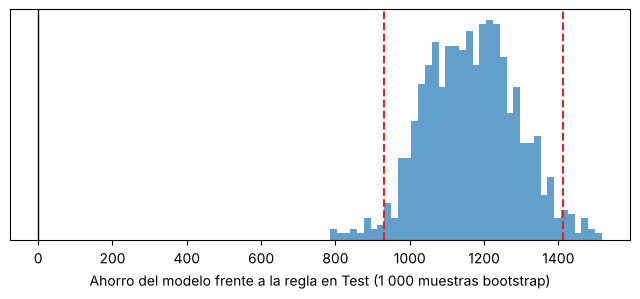

In [15]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(ahorro_boot, bins=40, color='tab:blue', alpha=0.7)
ax.axvline(0, color='black', lw=1); ax.axvline(lo, color='tab:red', ls='--'); ax.axvline(hi, color='tab:red', ls='--')
ax.set_xlabel('Ahorro del modelo frente a la regla en Test (1 000 muestras bootstrap)'); ax.set_yticks([])
plt.show()

> 📝 **Al formulario (pregunta 7):** copia el costo del modelo, de la regla y de "no llamar a nadie" en Test, el ahorro y su intervalo. ¿El intervalo excluye el cero? ¿Por qué el Test se mira **una sola vez** y al final?

# Paso 8 · La ficha ejecutiva (15 min)

La celda siguiente junta **todas tus cifras** en un resumen. Con él, escribe en el formulario la ficha para el gerente: **una recomendación en lenguaje no técnico**.

La ficha tiene cinco partes:

1. **La pregunta:** qué decisión apoya el modelo.
2. **La recomendación:** a quién llamar y con qué modelo.
3. **La cifra principal:** cuánto ahorra frente a la regla actual, en Test.
4. **Cuánto confiar:** el intervalo, y si las probabilidades del modelo son creíbles.
5. **Tres limitaciones:** por ejemplo, que llamar no evita todos los impagos, que los costos son supuestos, que los datos son de otro país y otra época, o que el modelo puede tratar distinto a algunos grupos.

In [16]:
print('=' * 78)
print(f'RESUMEN · Escenario {ESCENARIO}')
print('=' * 78)
print(f'Decisión: llamar a un cliente para ofrecerle un plan de pagos si p > {UMBRAL:.2f} '
      f'(llamar {esc["llamar"]}, impago {esc["impago"]}).')
print(f'Línea base: regla del atraso (2+ meses en septiembre). P(impago | alerta) en Train = '
      f'{con_alerta_impago / tabla.loc[1, "Total"]:.2f}.')
fila = resumen_seg.iloc[-1]
print(f'Segmento "{esc["segmento"]}": tasa estimada {fila["Media"]:.2f} '
      f'(IC 95 % {fila["IC 95 % desde"]:.2f} a {fila["IC 95 % hasta"]:.2f}); '
      f'P(más riesgoso que la cartera) = {fila["P(más riesgoso que la cartera)"]:.2f}.')
print(f'Modelo elegido en Validation: {ELEGIDO} '
      f'(AUC {comparacion.loc[ELEGIDO, "AUC"]:.3f}, Brier {comparacion.loc[ELEGIDO, "Brier"]:.3f}).')
print(f'En Test: llamaría a {int((p_test_modelo > UMBRAL).sum())} de {len(y_test)} clientes. '
      f'Costo {c_modelo.sum():,.0f} frente a {c_regla.sum():,.0f} de la regla '
      f'y {c_nadie.sum():,.0f} de no llamar a nadie.')
print(f'Ahorro frente a la regla: {c_regla.sum() - c_modelo.sum():,.0f} (IC 95 %: {lo:,.0f} a {hi:,.0f}).')
print('=' * 78)

RESUMEN · Escenario 0
Decisión: llamar a un cliente para ofrecerle un plan de pagos si p > 0.17 (llamar 1, impago 6).
Línea base: regla del atraso (2+ meses en septiembre). P(impago | alerta) en Train = 0.70.
Segmento "casados": tasa estimada 0.23 (IC 95 % 0.22 a 0.24); P(más riesgoso que la cartera) = 0.97.
Modelo elegido en Validation: Random Forest (AUC 0.783, Brier 0.135).
En Test: llamaría a 2782 de 6000 clientes. Costo 4,798 frente a 5,964 de la regla y 7,962 de no llamar a nadie.
Ahorro frente a la regla: 1,166 (IC 95 %: 932 a 1,413).


> 📝 **Al formulario (pregunta 8):** escribe la ficha ejecutiva con las cinco partes. Máximo 12 líneas, sin palabras técnicas que el gerente no conozca (si usas "AUC" o "Brier", explícalos en una frase).

---

## Si terminas antes

- Cambia `ESCENARIO` por otro número y vuelve a ejecutar todo (*Kernel → Restart & Run All*). ¿Cambia el modelo elegido? ¿Cambia la recomendación?
- En el Paso 6, ¿qué pasa si el costo de llamar sube al doble?

## Checklist del proyecto

- [ ] ¿Escribí la decisión y calculé el umbral a mano?
- [ ] ¿Distingo P(impago | alerta) de P(alerta | impago)?
- [ ] ¿Respondí al gerente sobre su segmento con un intervalo, no solo con un número?
- [ ] ¿Comparé los modelos con la regla **en Validation**, con AUC y con Brier?
- [ ] ¿Elegí el modelo por el **costo**, no solo por el AUC?
- [ ] ¿Miré el Test **una sola vez**, al final, e informé el intervalo del ahorro?
- [ ] ¿La ficha la entendería alguien que no estuvo en el curso?